# Phân tích dữ liệu thương mại điện tử Olist (Brazil) và ứng dụng học máy

Notebook này chứa toàn bộ phần xử lý số liệu cho báo cáo. Thứ tự các phần trùng với thứ tự các mục trong báo cáo:

1. Đọc dữ liệu và tổng quan các bảng
2. Tiền xử lý, tạo biến mới
3. Xu hướng đơn hàng và doanh thu theo thời gian
4. Danh mục sản phẩm, giá và thanh toán
5. Khách hàng và phân bố địa lý
6. Giao hàng và mức độ hài lòng
7. Phân khúc khách hàng bằng RFM + K-Means
8. Mô hình dự đoán đánh giá thấp (1–2 sao)

Dữ liệu: *Brazilian E-Commerce Public Dataset by Olist* (Kaggle), đặt trong thư mục `data/`.
Biểu đồ được lưu vào `outputs/figures/`, các con số chính được lưu vào `outputs/results.json`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA, OUT = Path("data"), Path("outputs")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
R = {}  # các con số dùng trong báo cáo

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
MAIN, GREY = "#2b6cb0", "#a0aec0"

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Đọc dữ liệu và tổng quan các bảng

In [2]:
def read(name, dates=()):
    return pd.read_csv(DATA / f"olist_{name}_dataset.csv", parse_dates=list(dates))

orders = read("orders", ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                         "order_delivered_customer_date", "order_estimated_delivery_date"])
items = read("order_items", ["shipping_limit_date"])
payments = read("order_payments")
reviews = read("order_reviews", ["review_creation_date", "review_answer_timestamp"])
customers = read("customers")
sellers = read("sellers")
products = read("products")
geo = read("geolocation")
trans = pd.read_csv(DATA / "product_category_name_translation.csv")

tables = dict(orders=orders, order_items=items, order_payments=payments, order_reviews=reviews,
              customers=customers, sellers=sellers, products=products, geolocation=geo,
              category_translation=trans)
overview = pd.DataFrame({k: {"số dòng": len(v), "số cột": v.shape[1],
                             "ô bị thiếu": int(v.isna().sum().sum()),
                             "dòng trùng lặp": int(v.duplicated().sum())} for k, v in tables.items()}).T
R["tables"] = overview.to_dict("index")
overview

,số dòng,số cột,ô bị thiếu,dòng trùng lặp
orders,99441,8,4908,0
order_items,112650,7,0,0
order_payments,103886,5,0,0
order_reviews,99224,7,145903,0
customers,99441,5,0,0
sellers,3095,4,0,0
products,32951,9,2448,0
geolocation,1000163,5,0,261831
category_translation,71,2,0,0


In [3]:
# Các cột có giá trị thiếu
missing = {(k, c): n for k, v in tables.items() for c, n in v.isna().sum().items() if n}
pd.Series(missing, name="số ô thiếu").to_frame()

số ô thiếu
orders        order_approved_at                     160
              order_delivered_carrier_date         1783
              order_delivered_customer_date        2965
order_reviews review_comment_title                87656
              review_comment_message              58247
products      product_category_name                 610
              product_name_lenght                   610
              product_description_lenght            610
              product_photos_qty                    610
              product_weight_g                        2
              product_length_cm                       2
              product_height_cm                       2
              product_width_cm                        2

In [4]:
R["order_status"] = orders.order_status.value_counts().to_dict()
R["date_range"] = [str(orders.order_purchase_timestamp.min()), str(orders.order_purchase_timestamp.max())]
print("Khoảng thời gian:", R["date_range"])
orders.order_status.value_counts().to_frame("số đơn")

Khoảng thời gian: ['2016-09-04 21:15:19', '2018-10-17 17:30:18']


,số đơn
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


## 2. Tiền xử lý dữ liệu

Các bước chính:
- Dịch tên danh mục sang tiếng Anh, danh mục thiếu gán `unknown`.
- Một số đơn có nhiều hơn một review → giữ review được trả lời sau cùng.
- Geolocation: bỏ tọa độ nằm ngoài lãnh thổ Brazil, lấy trung bình tọa độ theo tiền tố mã bưu chính.
- Chỉ giữ đơn `delivered` có đủ ngày giao thực tế; tạo các biến thời gian giao hàng.
- Gộp item theo đơn để có giá trị đơn hàng (giá + phí vận chuyển).

In [5]:
products = products.merge(trans, on="product_category_name", how="left")
products["category"] = products.product_category_name_english.fillna("unknown")

R["reviews_dup_orders"] = int(reviews.order_id.duplicated().sum())
reviews = reviews.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")

geo = geo[geo.geolocation_lat.between(-34, 6) & geo.geolocation_lng.between(-74, -34)]
zip_ll = geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].mean()

dlv = orders[(orders.order_status == "delivered") & orders.order_delivered_customer_date.notna()].copy()
days = lambda a, b: (a - b).dt.total_seconds() / 86400
dlv["delivery_days"] = days(dlv.order_delivered_customer_date, dlv.order_purchase_timestamp)
dlv["estimated_days"] = days(dlv.order_estimated_delivery_date, dlv.order_purchase_timestamp)
dlv["delay_days"] = days(dlv.order_delivered_customer_date, dlv.order_estimated_delivery_date)
dlv["is_late"] = (dlv.delay_days > 0).astype(int)
dlv["approve_hours"] = days(dlv.order_approved_at, dlv.order_purchase_timestamp) * 24
dlv["carrier_days"] = days(dlv.order_delivered_carrier_date, dlv.order_purchase_timestamp)

it = items.merge(products[["product_id", "category", "product_weight_g", "product_photos_qty",
                           "product_description_lenght"]], on="product_id", how="left")
order_val = it.groupby("order_id").agg(price=("price", "sum"), freight=("freight_value", "sum"),
                                       n_items=("order_item_id", "count"), n_sellers=("seller_id", "nunique"),
                                       weight=("product_weight_g", "sum"), photos=("product_photos_qty", "mean"),
                                       desc_len=("product_description_lenght", "mean"),
                                       category=("category", "first"), seller_id=("seller_id", "first"))
order_val["revenue"] = order_val.price + order_val.freight
dlv = dlv.merge(order_val, on="order_id", how="inner").merge(customers, on="customer_id", how="left")
dlv["month"] = dlv.order_purchase_timestamp.dt.to_period("M")
R["n_delivered_clean"] = len(dlv)
print(f"Số đơn đã giao dùng để phân tích: {len(dlv):,}")
dlv[["delivery_days", "estimated_days", "delay_days", "price", "freight", "revenue", "n_items"]].describe().T

Số đơn đã giao dùng để phân tích: 96,470


,count,mean,std,min,25%,50%,75%,max
delivery_days,"96,470.00",12.56,9.55,0.53,6.77,10.22,15.72,209.63
estimated_days,"96,470.00",23.74,8.76,2.01,18.33,23.23,28.41,155.14
delay_days,"96,470.00",-11.18,10.18,-146.02,-16.24,-11.95,-6.39,188.98
price,"96,470.00",137.04,209.05,0.85,45.90,86.50,149.90,"13,440.00"
freight,"96,470.00",22.79,21.56,0.00,13.85,17.17,24.02,"1,794.96"
revenue,"96,470.00",159.83,218.80,9.59,61.85,105.28,176.26,"13,664.08"
n_items,"96,470.00",1.14,0.54,1.00,1.00,1.00,1.00,21.00


## 3. Xu hướng đơn hàng và doanh thu theo thời gian

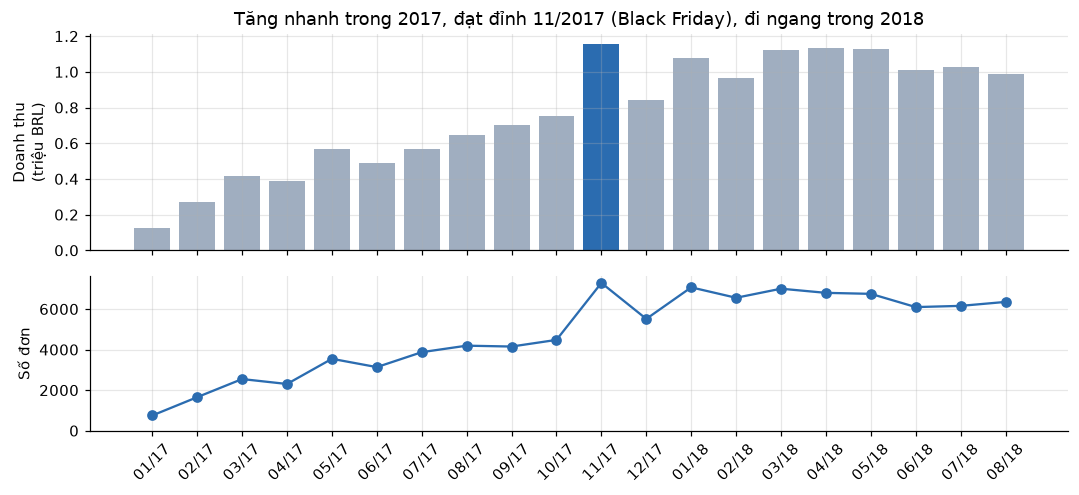

In [6]:
R["totals"] = {"orders": len(dlv), "revenue": round(dlv.revenue.sum()), "aov": round(dlv.revenue.mean(), 2),
               "aov_median": round(dlv.revenue.median(), 2), "customers": int(dlv.customer_unique_id.nunique()),
               "sellers": int(items.seller_id.nunique()), "products": int(items.product_id.nunique()),
               "freight_share": round(dlv.freight.sum() / dlv.revenue.sum(), 4)}
# 2016 rất ít dữ liệu, tháng 9-10/2018 chưa đủ -> chỉ vẽ 01/2017 - 08/2018
m = dlv[(dlv.month >= "2017-01") & (dlv.month <= "2018-08")].groupby("month").agg(
    orders=("order_id", "count"), revenue=("revenue", "sum"))
R["monthly"] = [{"month": str(k), "orders": int(v.orders), "revenue": round(v.revenue)} for k, v in m.iterrows()]

# Hai panel chung trục thời gian thay cho trục tung kép (dễ gây hiểu sai tỷ lệ)
labels = [k.strftime("%m/%y") for k in m.index]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
a1.bar(labels, m.revenue / 1e6, color=[MAIN if str(k) == "2017-11" else GREY for k in m.index])
a1.set_ylabel("Doanh thu\n(triệu BRL)")
a1.set_title("Tăng nhanh trong 2017, đạt đỉnh 11/2017 (Black Friday), đi ngang trong 2018")
a2.plot(labels, m.orders, color=MAIN, marker="o", lw=1.5)
a2.set_ylabel("Số đơn"); a2.set_ylim(0, None)
plt.setp(a2.get_xticklabels(), rotation=45)
save("01_monthly")

In [7]:
y = dlv.order_purchase_timestamp
jan_aug = lambda year: dlv[(y.dt.year == year) & (y.dt.month <= 8)]
R["yoy_jan_aug"] = {"orders_2017": len(jan_aug(2017)), "orders_2018": len(jan_aug(2018)),
                    "rev_2017": round(jan_aug(2017).revenue.sum()), "rev_2018": round(jan_aug(2018).revenue.sum())}
daily = dlv.groupby(y.dt.date).size()
R["top_days"] = {str(k): int(v) for k, v in daily.nlargest(5).items()}
R["median_daily_2017_11"] = float(daily[[str(d).startswith("2017-11") for d in daily.index]].median())
print(R["yoy_jan_aug"]); print("5 ngày nhiều đơn nhất:", R["top_days"])

{'orders_2017': 21997, 'orders_2018': 52777, 'rev_2017': 3472704, 'rev_2018': 8450535}
5 ngày nhiều đơn nhất: {'2017-11-24': 1147, '2017-11-25': 487, '2017-11-27': 395, '2017-11-26': 382, '2017-11-28': 371}


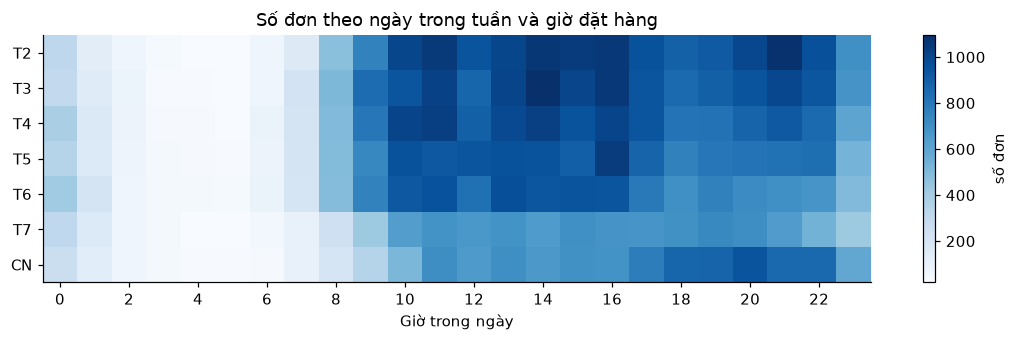

In [8]:
R["dow"] = y.dt.dayofweek.value_counts().sort_index().tolist()   # 0 = thứ Hai
R["hour"] = y.dt.hour.value_counts().sort_index().tolist()
heat = dlv.pivot_table(index=y.dt.dayofweek, columns=y.dt.hour, values="order_id", aggfunc="count")
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), ["T2", "T3", "T4", "T5", "T6", "T7", "CN"])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Giờ trong ngày"); ax.grid(False)
ax.set_title("Số đơn theo ngày trong tuần và giờ đặt hàng")
fig.colorbar(im, ax=ax, label="số đơn")
save("02_dow_hour")

## 4. Danh mục sản phẩm, giá và phương thức thanh toán

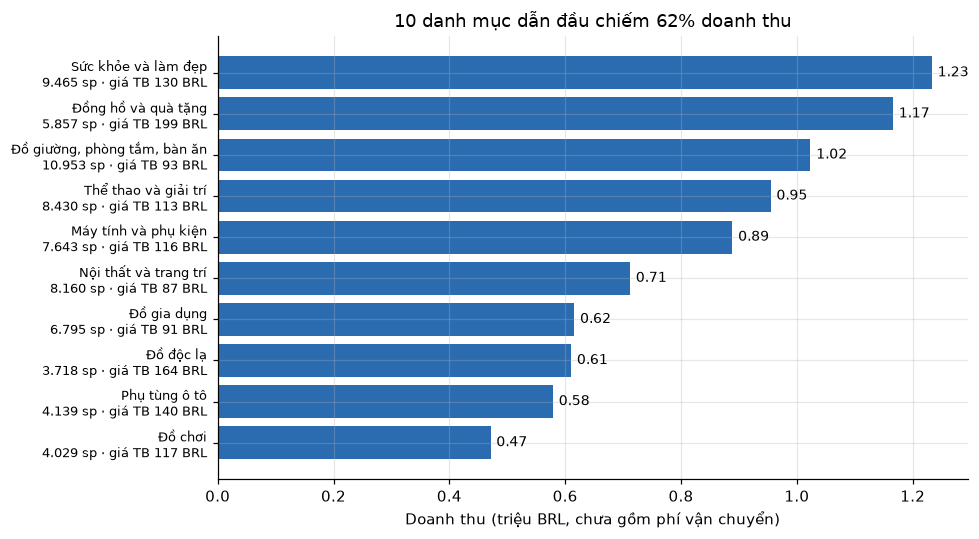

,revenue,items,avg_price
category,,,
health_beauty,"1,233,131.72",9465,130.28
watches_gifts,"1,165,898.98",5857,199.06
bed_bath_table,"1,023,434.76",10953,93.44
sports_leisure,"954,673.55",8430,113.25
computers_accessories,"888,613.62",7643,116.27
furniture_decor,"711,927.69",8160,87.25
housewares,"615,628.69",6795,90.60
cool_stuff,"610,204.10",3718,164.12
auto,"578,849.35",4139,139.85


In [9]:
itd = it[it.order_id.isin(dlv.order_id)]
cat = itd.groupby("category").agg(revenue=("price", "sum"), items=("order_item_id", "count"),
                                  avg_price=("price", "mean")).sort_values("revenue", ascending=False)
R["n_categories"] = int((cat.index != "unknown").sum())
R["top_categories"] = cat.head(10).round(1).reset_index().to_dict("records")
R["top10_cat_share"] = round(cat.revenue.head(10).sum() / cat.revenue.sum(), 4)
R["n_cat_for_80pct"] = int((cat.revenue.cumsum() / cat.revenue.sum() < 0.8).sum() + 1)
R["price_quantiles"] = {str(q): round(itd.price.quantile(q), 2) for q in (0.25, 0.5, 0.75, 0.95)}

CAT_VI = {"health_beauty": "Sức khỏe và làm đẹp", "watches_gifts": "Đồng hồ và quà tặng",
          "bed_bath_table": "Đồ giường, phòng tắm, bàn ăn", "sports_leisure": "Thể thao và giải trí",
          "computers_accessories": "Máy tính và phụ kiện", "furniture_decor": "Nội thất và trang trí",
          "housewares": "Đồ gia dụng", "cool_stuff": "Đồ độc lạ", "auto": "Phụ tùng ô tô", "toys": "Đồ chơi"}
top = cat.head(10)[::-1]
# Ghi số sản phẩm bán ra và giá trung bình ngay dưới tên danh mục thay cho một bảng riêng
names = [CAT_VI.get(k, k) + "\n" + f"{v['items']:,.0f}".replace(",", ".") + f" sp · giá TB {v.avg_price:.0f} BRL"
         for k, v in top.iterrows()]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(names, top.revenue / 1e6, color=MAIN)
ax.tick_params(axis="y", labelsize=8.5)
for i, v in enumerate(top.revenue / 1e6):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Doanh thu (triệu BRL, chưa gồm phí vận chuyển)")
ax.set_title(f"10 danh mục dẫn đầu chiếm {R['top10_cat_share']:.0%} doanh thu")
save("03_top_categories")
cat.head(10)

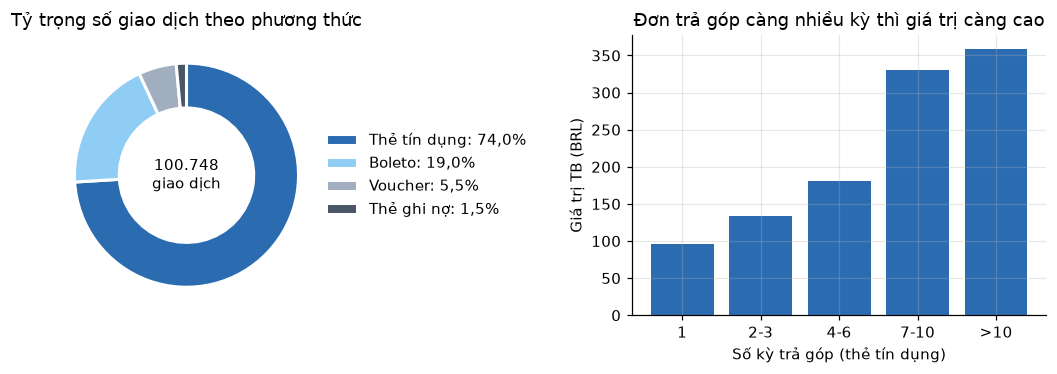

,n,value,tỷ trọng số giao dịch,tỷ trọng giá trị
payment_type,,,,
boleto,19191,"2,769,932.58",0.19,0.18
credit_card,74579,"12,100,070.20",0.74,0.78
debit_card,1485,"208,066.88",0.01,0.01
voucher,5493,"343,013.19",0.05,0.02


In [10]:
pay = payments[payments.order_id.isin(dlv.order_id)]
pt = pay.groupby("payment_type").agg(n=("order_id", "count"), value=("payment_value", "sum"))
pt["tỷ trọng số giao dịch"] = pt.n / pt.n.sum()
pt["tỷ trọng giá trị"] = pt.value / pt.value.sum()
R["payment_types"] = pt[["tỷ trọng số giao dịch", "tỷ trọng giá trị"]].round(4).to_dict("index")

cc = pay[pay.payment_type == "credit_card"]
R["installments_mean"] = round(cc.payment_installments.mean(), 2)
R["installments_share_gt1"] = round((cc.payment_installments > 1).mean(), 4)
inst = cc.groupby(pd.cut(cc.payment_installments, [0, 1, 3, 6, 10, 24], labels=["1", "2-3", "4-6", "7-10", ">10"]),
                  observed=True).agg(n=("order_id", "count"), avg_value=("payment_value", "mean"))
inst["share"] = inst.n / inst.n.sum()
R["installments"] = inst.round(4).reset_index().astype({"payment_installments": str}).to_dict("records")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
VI = {"credit_card": "Thẻ tín dụng", "boleto": "Boleto", "voucher": "Voucher", "debit_card": "Thẻ ghi nợ"}
s = pt.sort_values("n", ascending=False)
pct = lambda v: f"{v * 100:.1f}%".replace(".", ",")
wedges, _ = a1.pie(s.n, startangle=90, counterclock=False, colors=[MAIN, "#90cdf4", GREY, "#4a5568"],
                   wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2})
a1.legend(wedges, [f"{VI[k]}: {pct(v)}" for k, v in s["tỷ trọng số giao dịch"].items()],
          loc="center left", bbox_to_anchor=(0.95, 0.5), frameon=False)
a1.text(0, 0, f"{s.n.sum():,}\ngiao dịch".replace(",", "."), ha="center", va="center")
a1.set_title("Tỷ trọng số giao dịch theo phương thức")
a2.bar(inst.index.astype(str), inst.avg_value, color=MAIN)
a2.set_xlabel("Số kỳ trả góp (thẻ tín dụng)"); a2.set_ylabel("Giá trị TB (BRL)")
a2.set_title("Đơn trả góp càng nhiều kỳ thì giá trị càng cao")
save("04_payments")
pt

## 5. Khách hàng và phân bố địa lý

In [11]:
st = dlv.groupby("customer_state").agg(orders=("order_id", "count"), aov=("revenue", "mean"),
                                       freight=("freight", "mean"), days=("delivery_days", "mean"),
                                       late=("is_late", "mean")).sort_values("orders", ascending=False)
st["share"] = st.orders / st.orders.sum()
R["states"] = st.round(4).reset_index().to_dict("records")
R["seller_states"] = sellers.seller_state.value_counts(normalize=True).head(5).round(4).to_dict()
seller_rev = itd.groupby("seller_id").price.sum().sort_values(ascending=False)
R["top10pct_sellers_rev_share"] = round(seller_rev.head(len(seller_rev) // 10).sum() / seller_rev.sum(), 4)
cust_orders = dlv.groupby("customer_unique_id").order_id.nunique()
R["repeat_rate"] = round((cust_orders > 1).mean(), 4)
R["orders_per_customer_dist"] = cust_orders.clip(upper=4).value_counts().sort_index().to_dict()
print("Tỷ lệ khách mua từ 2 đơn trở lên:", R["repeat_rate"])
print("Top 10% người bán chiếm doanh thu:", R["top10pct_sellers_rev_share"])
st.head(10)

Tỷ lệ khách mua từ 2 đơn trở lên: 0.03
Top 10% người bán chiếm doanh thu: 0.6712


,orders,aov,freight,days,late,share
customer_state,,,,,,
SP,40494,142.45,17.33,8.76,0.06,0.42
RJ,12350,166.43,23.95,15.31,0.13,0.13
MG,11354,160.20,23.46,12.01,0.06,0.12
RS,5344,161.17,24.81,15.30,0.07,0.06
PR,4923,158.79,23.49,11.99,0.05,0.05
SC,3546,167.83,24.85,14.95,0.10,0.04
BA,3256,181.55,29.96,19.34,0.14,0.03
DF,2080,166.41,23.86,12.97,0.07,0.02
ES,1995,159.23,24.57,15.79,0.12,0.02


Bản đồ choropleth theo bang. Ranh giới 27 bang lấy từ file GeoJSON công khai (`data/geo/brazil_states.geojson`,
nguồn: dự án *click_that_hood*), vẽ trực tiếp bằng Matplotlib nên không cần cài thêm thư viện bản đồ.

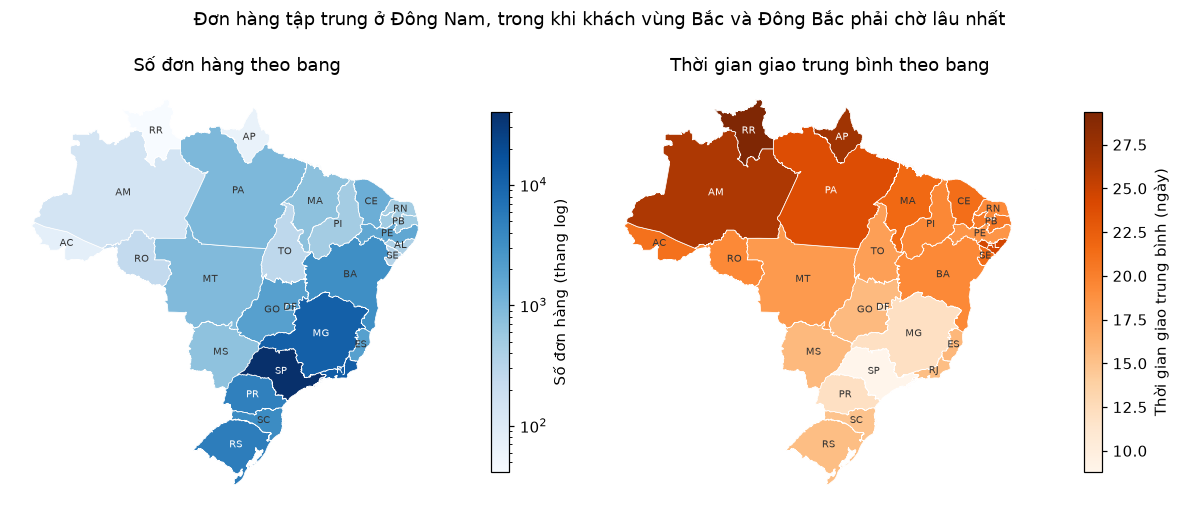

In [12]:
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Polygon

geo_br = json.loads((DATA / "geo" / "brazil_states.geojson").read_text(encoding="utf-8"))

def centroid(ring):
    # trọng tâm đa giác theo công thức shoelace (trung bình các đỉnh bị lệch về phía bờ biển nhiều điểm)
    x, y = np.asarray(ring).T
    cross = x * np.roll(y, -1) - np.roll(x, -1) * y
    a = cross.sum() / 2
    return ((x + np.roll(x, -1)) * cross).sum() / (6 * a), ((y + np.roll(y, -1)) * cross).sum() / (6 * a)

def draw_map(ax, values, norm, cmap, label):
    for f in geo_br["features"]:
        g = f["geometry"]
        polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        for poly in polys:
            ax.add_patch(Polygon(poly[0], facecolor=cmap(norm(values[f["properties"]["sigla"]])),
                                 edgecolor="white", lw=0.5))
        x, y = centroid(max(polys, key=lambda p: len(p[0]))[0])   # ghi mã bang ở phần lãnh thổ lớn nhất
        dark = norm(values[f["properties"]["sigla"]]) > 0.65   # chữ trắng trên nền đậm để đủ tương phản
        ax.text(x, y, f["properties"]["sigla"], ha="center", va="center", fontsize=6.5,
                color="white" if dark else "#333333")
    ax.autoscale_view(); ax.set_aspect("equal"); ax.axis("off")
    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.75, label=label)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5))
draw_map(a1, st.orders, LogNorm(st.orders.min(), st.orders.max()), plt.cm.Blues, "Số đơn hàng (thang log)")
draw_map(a2, st.days, Normalize(st.days.min(), st.days.max()), plt.cm.Oranges, "Thời gian giao trung bình (ngày)")
a1.set_title("Số đơn hàng theo bang"); a2.set_title("Thời gian giao trung bình theo bang")
fig.suptitle("Đơn hàng tập trung ở Đông Nam, trong khi khách vùng Bắc và Đông Bắc phải chờ lâu nhất", fontsize=12)
save("05a_map")

In [13]:
# Khoảng cách người bán - khách hàng (công thức haversine, km)
dlv = dlv.merge(sellers[["seller_id", "seller_zip_code_prefix", "seller_state"]], on="seller_id", how="left")
c = zip_ll.reindex(dlv.customer_zip_code_prefix).to_numpy()
s = zip_ll.reindex(dlv.seller_zip_code_prefix).to_numpy()
lat1, lng1, lat2, lng2 = map(np.radians, (c[:, 0], c[:, 1], s[:, 0], s[:, 1]))
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
dlv["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))
dlv["same_state"] = (dlv.customer_state == dlv.seller_state).astype(int)
R["distance_median"] = round(dlv.distance_km.median(), 1)
R["same_state_share"] = round(dlv.same_state.mean(), 4)
R["corr_distance_days"] = round(dlv.distance_km.corr(dlv.delivery_days, method="spearman"), 3)
R["corr_distance_freight"] = round(dlv.distance_km.corr(dlv.freight, method="spearman"), 3)
{k: R[k] for k in ["distance_median", "same_state_share", "corr_distance_days", "corr_distance_freight"]}

{'distance_median': np.float64(433.8),
 'same_state_share': np.float64(0.3597),
 'corr_distance_days': np.float64(0.543),
 'corr_distance_freight': np.float64(0.584)}

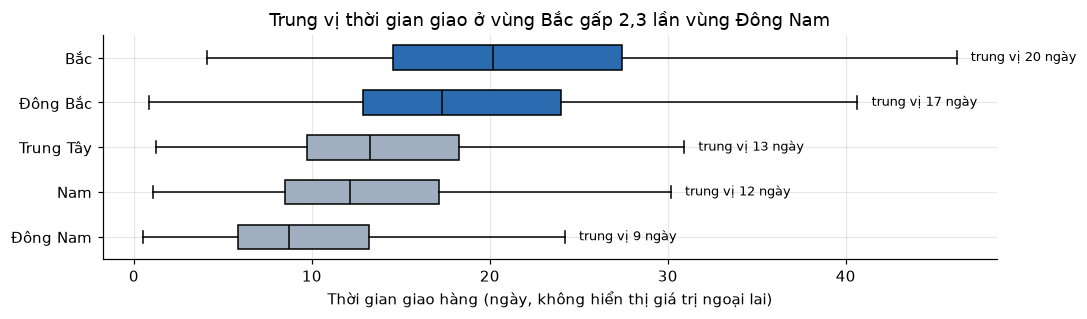

,count,mean,std,min,25%,50%,75%,90%,max
region,,,,,,,,,
Đông Nam,"66,193.00",10.75,8.50,0.53,5.84,8.71,13.19,19.62,209.63
Nam,"13,813.00",14.03,8.44,1.07,8.48,12.12,17.15,24.03,186.24
Trung Tây,"5,624.00",15.02,8.39,1.26,9.74,13.28,18.27,24.22,181.06
Đông Bắc,"9,044.00",20.01,12.25,0.86,12.89,17.32,24.00,33.11,194.85
Bắc,"1,796.00",22.59,13.09,4.12,14.55,20.16,27.44,36.56,195.63


In [14]:
# Phân phối thời gian giao theo 5 vùng địa lý của Brazil (phân vùng của IBGE)
REGION = {**dict.fromkeys(["AC", "AM", "AP", "PA", "RO", "RR", "TO"], "Bắc"),
          **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Đông Bắc"),
          **dict.fromkeys(["DF", "GO", "MS", "MT"], "Trung Tây"),
          **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Đông Nam"),
          **dict.fromkeys(["PR", "RS", "SC"], "Nam")}
dlv["region"] = dlv.customer_state.map(REGION)
reg = dlv.groupby("region").delivery_days.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).sort_values("50%")
R["region_delivery"] = reg[["count", "25%", "50%", "75%", "90%"]].round(1).to_dict("index")

fig, ax = plt.subplots(figsize=(10, 3))
bp = ax.boxplot([dlv.loc[dlv.region == r, "delivery_days"] for r in reg.index], orientation="horizontal",
                tick_labels=reg.index, showfliers=False, patch_artist=True, widths=0.55,
                medianprops={"color": "black"})
for box, r in zip(bp["boxes"], reg.index):
    box.set_facecolor(MAIN if r in ("Bắc", "Đông Bắc") else GREY)
for i, (r, v) in enumerate(reg.iterrows(), start=1):
    right_cap = bp["caps"][2 * i - 1].get_xdata()[0]   # đầu râu bên phải của hộp thứ i
    ax.text(right_cap + 0.8, i, f"trung vị {v['50%']:.0f} ngày", va="center", fontsize=8.5)
ax.set_xlabel("Thời gian giao hàng (ngày, không hiển thị giá trị ngoại lai)")
ratio = f"{reg.loc['Bắc', '50%'] / reg.loc['Đông Nam', '50%']:.1f}".replace(".", ",")
ax.set_title(f"Trung vị thời gian giao ở vùng Bắc gấp {ratio} lần vùng Đông Nam")
save("05b_region_box")
reg

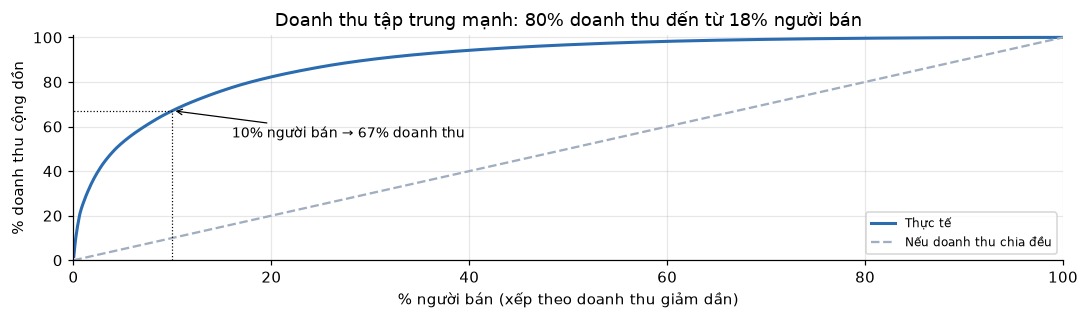

In [15]:
# Đường Pareto (Lorenz): tỷ trọng doanh thu cộng dồn theo người bán, sắp xếp giảm dần
cum = seller_rev.cumsum() / seller_rev.sum() * 100
pct = np.arange(1, len(cum) + 1) / len(cum) * 100
R["pct_sellers_for_80pct_rev"] = round(float(pct[np.searchsorted(cum.to_numpy(), 80)]), 1)
top10 = R["top10pct_sellers_rev_share"] * 100

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(pct, cum, color=MAIN, lw=2, label="Thực tế")
ax.plot([0, 100], [0, 100], ls="--", color=GREY, label="Nếu doanh thu chia đều")
ax.plot([10, 10, 0], [0, top10, top10], ls=":", color="black", lw=0.8)
ax.annotate(f"10% người bán → {top10:.0f}% doanh thu", (10, top10), xytext=(16, top10 - 12), fontsize=9,
            arrowprops={"arrowstyle": "->", "lw": 0.8})
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
ax.set_xlabel("% người bán (xếp theo doanh thu giảm dần)"); ax.set_ylabel("% doanh thu cộng dồn")
ax.set_title(f"Doanh thu tập trung mạnh: 80% doanh thu đến từ {R['pct_sellers_for_80pct_rev']:.0f}% người bán")
ax.legend(loc="lower right", fontsize=8)
save("05c_seller_pareto")

## 6. Giao hàng và mức độ hài lòng

In [16]:
dlv = dlv.merge(reviews[["order_id", "review_score", "review_comment_message"]], on="order_id", how="left")
R["delivery"] = {"mean": round(dlv.delivery_days.mean(), 1), "median": round(dlv.delivery_days.median(), 1),
                 "p90": round(dlv.delivery_days.quantile(0.9), 1), "est_mean": round(dlv.estimated_days.mean(), 1),
                 "early_median": round(-dlv.delay_days.median(), 1), "late_rate": round(dlv.is_late.mean(), 4)}
late_m = dlv[(dlv.month >= "2017-01") & (dlv.month <= "2018-08")].groupby("month").is_late.mean()
R["late_by_month"] = {str(k): round(v, 4) for k, v in late_m.items()}
rv = dlv.dropna(subset=["review_score"])
R["review_dist"] = rv.review_score.value_counts(normalize=True).sort_index().round(4).to_dict()
R["review_mean"] = round(rv.review_score.mean(), 3)
R["delivery"]

{'mean': np.float64(12.6),
 'median': np.float64(10.2),
 'p90': np.float64(23.1),
 'est_mean': np.float64(23.7),
 'early_median': np.float64(11.9),
 'late_rate': np.float64(0.0811)}

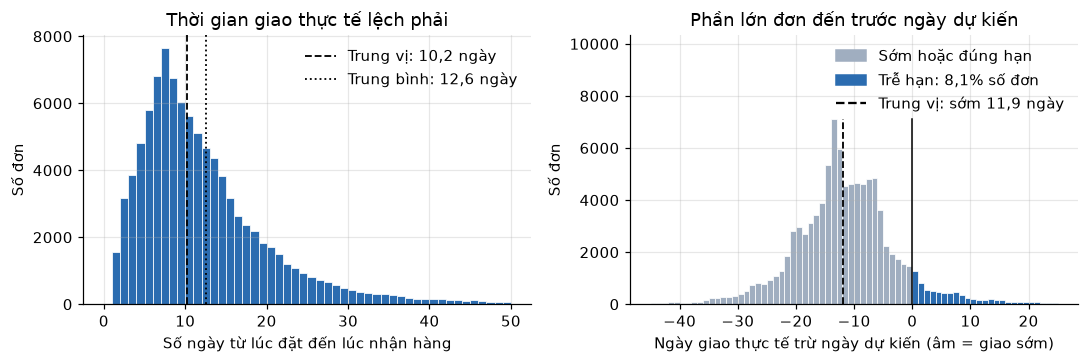

(np.float64(0.993), np.float64(0.9917))

In [17]:
# Phân phối thời gian giao (trái) và số ngày giao sớm/trễ so với ngày dự kiến (phải)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

dd, dl = dlv.delivery_days, dlv.delay_days
R["delivery_within_50"] = round((dd <= 50).mean(), 4)
R["delay_within_range"] = round(dl.between(-45, 25).mean(), 4)
num = lambda v: f"{v:.1f}".replace(".", ",")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.hist(dd, bins=np.arange(0, 51), color=MAIN, edgecolor="white", linewidth=0.5)
a1.axvline(dd.median(), color="black", ls="--", lw=1.2, label=f"Trung vị: {num(dd.median())} ngày")
a1.axvline(dd.mean(), color="black", ls=":", lw=1.2, label=f"Trung bình: {num(dd.mean())} ngày")
a1.legend(frameon=False)
a1.set_xlabel("Số ngày từ lúc đặt đến lúc nhận hàng"); a1.set_ylabel("Số đơn")
a1.set_title("Thời gian giao thực tế lệch phải")

_, edges, bars = a2.hist(dl, bins=np.arange(-45, 26), color=GREY, edgecolor="white", linewidth=0.5)
for left, bar in zip(edges, bars):
    if left >= 0:
        bar.set_facecolor(MAIN)
a2.set_ylim(0, max(b.get_height() for b in bars) * 1.45)   # chừa chỗ cho chú giải
a2.axvline(0, ymax=0.69, color="black", lw=1)
a2.axvline(dl.median(), ymax=0.69, color="black", ls="--", lw=1.2)
a2.legend(handles=[Patch(color=GREY, label="Sớm hoặc đúng hạn"),
                   Patch(color=MAIN, label=f"Trễ hạn: {num(dlv.is_late.mean() * 100)}% số đơn"),
                   Line2D([], [], color="black", ls="--", label=f"Trung vị: sớm {num(-dl.median())} ngày")],
          frameon=False, loc="upper right")
a2.set_xlabel("Ngày giao thực tế trừ ngày dự kiến (âm = giao sớm)"); a2.set_ylabel("Số đơn")
a2.set_title("Phần lớn đơn đến trước ngày dự kiến")
save("06a_delivery_days")
R["delivery_within_50"], R["delay_within_range"]


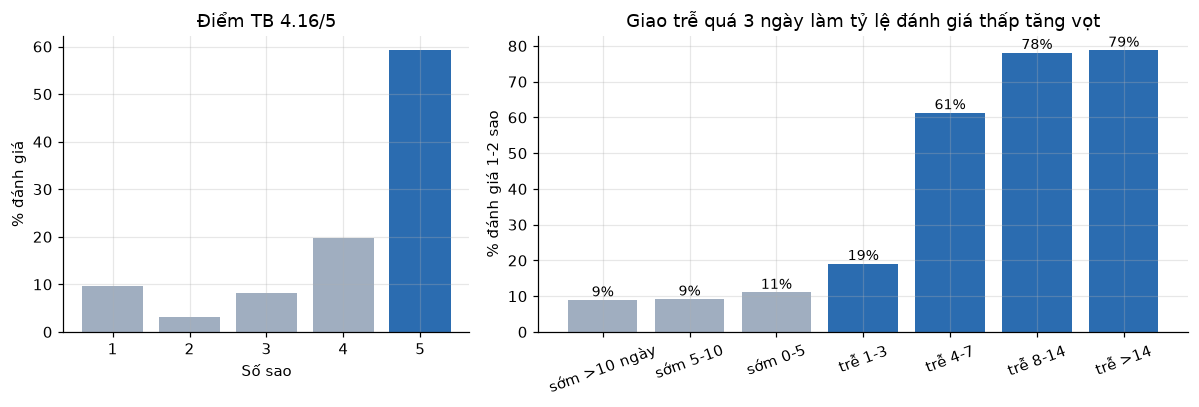

,n,score,low
delay_bucket,,,
sớm >10 ngày,56905,4.32,0.09
sớm 5-10,22442,4.28,0.09
sớm 0-5,8816,4.15,0.11
trễ 1-3,2636,3.77,0.19
trễ 4-7,1773,2.32,0.61
trễ 8-14,1748,1.74,0.78
trễ >14,1504,1.71,0.79


In [18]:
bins = [-1e9, -10, -5, 0, 3, 7, 14, 1e9]
labels = ["sớm >10 ngày", "sớm 5-10", "sớm 0-5", "trễ 1-3", "trễ 4-7", "trễ 8-14", "trễ >14"]
rv = rv.assign(delay_bucket=pd.cut(rv.delay_days, bins, labels=labels))
db = rv.groupby("delay_bucket", observed=True).agg(n=("order_id", "count"), score=("review_score", "mean"),
                                                   low=("review_score", lambda s: (s <= 2).mean()))
R["review_by_delay"] = db.round(4).reset_index().astype({"delay_bucket": str}).to_dict("records")
R["review_by_late"] = rv.groupby("is_late").review_score.agg(["mean", lambda s: (s <= 2).mean()]).round(4).values.tolist()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
d = rv.review_score.value_counts(normalize=True).sort_index() * 100
a1.bar(d.index.astype(int), d, color=[GREY, GREY, GREY, GREY, MAIN])
a1.set_xlabel("Số sao"); a1.set_ylabel("% đánh giá"); a1.set_title(f"Điểm TB {R['review_mean']:.2f}/5")
a2.bar(db.index.astype(str), db.low * 100, color=[GREY] * 3 + [MAIN] * 4)
for i, v in enumerate(db.low * 100):
    a2.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
a2.set_ylabel("% đánh giá 1-2 sao"); a2.set_title("Giao trễ quá 3 ngày làm tỷ lệ đánh giá thấp tăng vọt")
plt.setp(a2.get_xticklabels(), rotation=20)
save("06_review_delay")
db

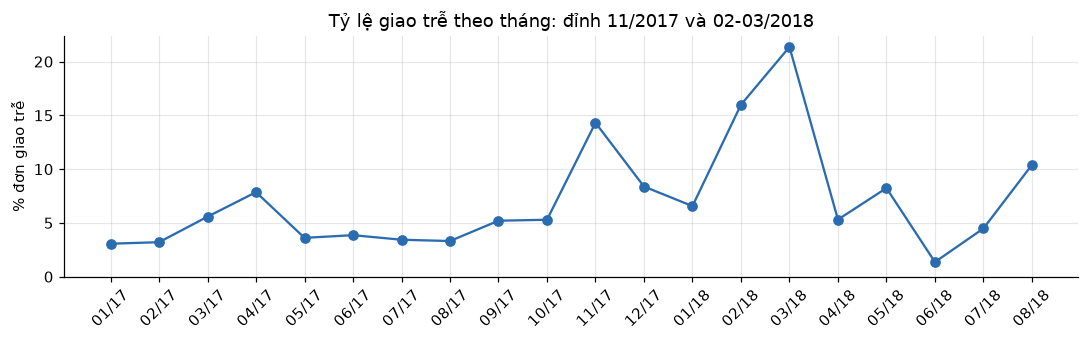

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot([k.strftime("%m/%y") for k in late_m.index], late_m * 100, marker="o", color=MAIN)
ax.set_ylabel("% đơn giao trễ"); ax.set_ylim(0, None)
ax.set_title("Tỷ lệ giao trễ theo tháng: đỉnh 11/2017 và 02-03/2018")
plt.setp(ax.get_xticklabels(), rotation=45)
save("07_late_by_month")

In [20]:
R["comment_share"] = round(rv.review_comment_message.notna().mean(), 4)
R["comment_share_low"] = round(rv[rv.review_score <= 2].review_comment_message.notna().mean(), 4)
cat_rv = rv.groupby("category").agg(n=("order_id", "count"), score=("review_score", "mean"))
cat_rv = cat_rv[cat_rv.n >= 500].sort_values("score")
R["worst_categories"] = cat_rv.head(5).round(2).reset_index().to_dict("records")
R["best_categories"] = cat_rv.tail(5).round(2).reset_index().to_dict("records")
# Đơn nhiều sản phẩm / nhiều người bán: thường bị giao tách nhiều lần
low_by_items = rv.groupby(rv.n_items.clip(upper=4)).agg(n=("order_id", "count"),
                                                        low=("review_score", lambda s: (s <= 2).mean()))
R["low_by_items"] = low_by_items.round(4).to_dict("index")
R["review_by_nsellers"] = rv.groupby(rv.n_sellers.clip(upper=2)).review_score.mean().round(3).to_dict()
print("Danh mục điểm thấp nhất:\n", cat_rv.head(5)); print(low_by_items)

Danh mục điểm thấp nhất:
                      n  score
category                     
office_furniture  1236   3.65
bed_bath_table    9072   4.01
unknown           1369   4.03
telephony         4052   4.06
furniture_decor   6167   4.07
             n  low
n_items            
1        86296 0.11
2         7319 0.25
3         1286 0.29
4          923 0.34


## 7. Phân khúc khách hàng bằng RFM + K-Means

- **Recency**: số ngày từ lần mua gần nhất đến ngày tham chiếu (ngày cuối dữ liệu + 1).
- **Frequency**: số đơn đã mua.
- **Monetary**: tổng tiền đã chi.

Ba biến bị lệch phải mạnh nên được lấy `log(1+x)` rồi chuẩn hóa trước khi đưa vào K-Means.

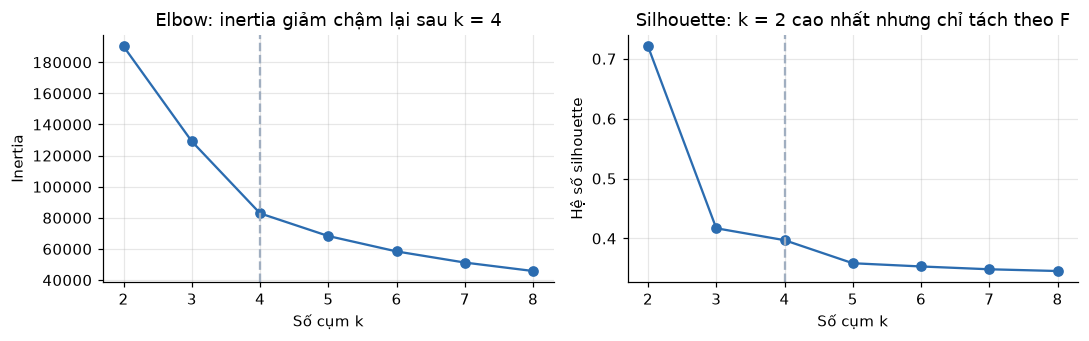

,recency,frequency,monetary
count,"93,350.00","93,350.00","93,350.00"
mean,237.95,1.03,165.17
std,152.59,0.21,226.30
min,1.00,1.00,9.59
25%,114.00,1.00,63.01
50%,219.00,1.00,107.78
75%,346.00,1.00,182.50
max,714.00,15.00,"13,664.08"


In [21]:
ref = dlv.order_purchase_timestamp.max() + pd.Timedelta(days=1)
rfm = dlv.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda s: (ref - s.max()).days),
    frequency=("order_id", "nunique"), monetary=("revenue", "sum"))
R["rfm_describe"] = rfm.describe().round(2).to_dict()
X = StandardScaler().fit_transform(np.log1p(rfm))

elbow, sil = {}, {}
sample = np.random.default_rng(SEED).choice(len(X), 10000, replace=False)  # silhouette tính trên mẫu 10k
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=SEED).fit(X)
    elbow[k], sil[k] = round(km.inertia_), round(silhouette_score(X[sample], km.labels_[sample]), 4)
R["kmeans_elbow"], R["kmeans_silhouette"] = elbow, sil

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
a1.plot(list(elbow), list(elbow.values()), marker="o", color=MAIN)
a1.set_ylabel("Inertia"); a1.set_title("Elbow: inertia giảm chậm lại sau k = 4")
a2.plot(list(sil), list(sil.values()), marker="o", color=MAIN)
a2.set_ylabel("Hệ số silhouette"); a2.set_title("Silhouette: k = 2 cao nhất nhưng chỉ tách theo F")
for a in (a1, a2):
    a.axvline(4, ls="--", color=GREY); a.set_xlabel("Số cụm k")
save("08_kmeans_k")
rfm.describe()

In [22]:
K = 4
rfm["cluster"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(X)
prof = rfm.groupby("cluster").agg(n=("recency", "size"), recency=("recency", "mean"),
                                  frequency=("frequency", "mean"), monetary=("monetary", "mean"),
                                  monetary_sum=("monetary", "sum"), repeat=("frequency", lambda s: (s > 1).mean()))
prof["share"] = prof.n / prof.n.sum()
prof["rev_share"] = prof.monetary_sum / prof.monetary_sum.sum()

# Đặt tên cụm theo đặc điểm (không phụ thuộc vào số thứ tự cụm)
names = {}
names[prof.frequency.idxmax()] = "Khách mua lặp lại"
rest = prof.drop(names)
names[rest.recency.idxmin()] = "Khách mới gần đây"
rest = rest.drop(names, errors="ignore")
names[rest.monetary.idxmax()] = "Khách chi tiêu cao, mua 1 lần"
names[rest.drop(names, errors="ignore").index[0]] = "Khách giá trị thấp, lâu không mua"
prof["segment"] = prof.index.map(names)
rfm["segment"] = rfm.cluster.map(names)
R["clusters"] = prof.round(4).reset_index().to_dict("records")
prof.set_index("segment")

,n,recency,frequency,monetary,monetary_sum,repeat,share,rev_share
segment,,,,,,,,
"Khách chi tiêu cao, mua 1 lần",32083,272.89,1.00,296.16,"9,501,661.03",0.00,0.34,0.62
Khách mua lặp lại,2801,220.29,2.11,308.53,"864,187.46",1.00,0.03,0.06
"Khách giá trị thấp, lâu không mua",42301,287.41,1.00,68.24,"2,886,816.70",0.00,0.45,0.19
Khách mới gần đây,16165,42.24,1.00,133.98,"2,165,729.64",0.00,0.17,0.14


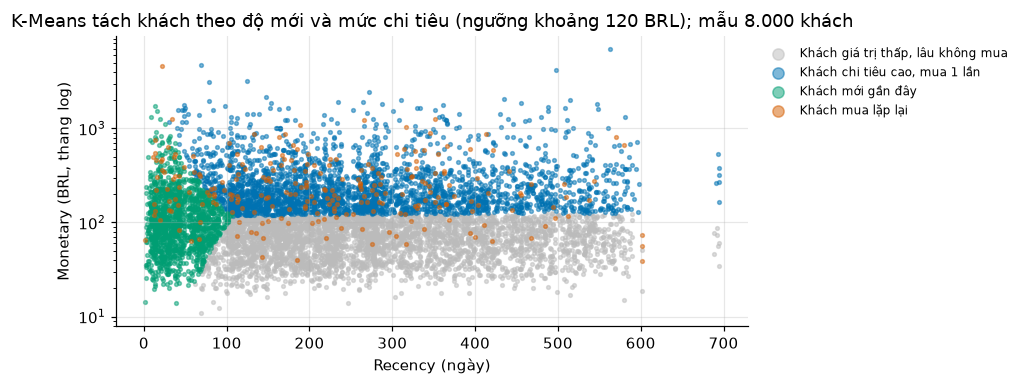

In [23]:
fig, ax = plt.subplots(figsize=(9, 3.6))
smp = rfm.sample(8000, random_state=SEED)
# Bảng màu Okabe-Ito (phân biệt được với người mù màu); nhóm nhỏ nhất vẽ sau cùng để không bị che
SEG_COLORS = {"Khách giá trị thấp, lâu không mua": "#BBBBBB", "Khách chi tiêu cao, mua 1 lần": "#0072B2",
              "Khách mới gần đây": "#009E73", "Khách mua lặp lại": "#D55E00"}
for seg, col in SEG_COLORS.items():
    g = smp[smp.segment == seg]
    ax.scatter(g.recency, g.monetary, s=6, alpha=0.5, label=seg, color=col)
ax.set_yscale("log"); ax.set_xlabel("Recency (ngày)"); ax.set_ylabel("Monetary (BRL, thang log)")
ax.set_title("K-Means tách khách theo độ mới và mức chi tiêu (ngưỡng khoảng 120 BRL); mẫu 8.000 khách")
ax.legend(markerscale=3, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
save("09_segments")

## 8. Mô hình dự đoán đánh giá thấp (1–2 sao)

**Bài toán**: tại thời điểm đơn hàng vừa giao xong (trước khi khách viết đánh giá), dự đoán đơn đó có bị đánh giá 1–2 sao hay không.
Vì vậy các biến về thời gian giao hàng được phép dùng, còn nội dung review thì không.

So sánh 3 mô hình: Logistic Regression, Random Forest, Gradient Boosting (HistGradientBoosting), cùng một mốc đơn giản là quy tắc "giao trễ ⇒ đánh giá thấp".
Dữ liệu chia 80/20 có phân tầng theo nhãn; dùng `class_weight="balanced"` vì nhãn dương chỉ khoảng 13%.

In [24]:
df = rv.copy()
df["low"] = (df.review_score <= 2).astype(int)
df["freight_ratio"] = df.freight / df.revenue
df["purchase_month"] = df.order_purchase_timestamp.dt.month
df["purchase_dow"] = df.order_purchase_timestamp.dt.dayofweek
df = df.merge(payments.groupby("order_id").agg(installments=("payment_installments", "max"),
                                               payment_type=("payment_type", "first")), on="order_id", how="left")
df["category_grp"] = df.category.where(df.category.isin(cat.index[:15]), "other")

num = ["delivery_days", "estimated_days", "delay_days", "is_late", "approve_hours", "carrier_days",
       "price", "freight", "freight_ratio", "n_items", "n_sellers", "weight", "photos", "desc_len",
       "distance_km", "same_state", "installments", "purchase_month", "purchase_dow"]
cats = ["customer_state", "payment_type", "category_grp"]
for col in num:
    df[col] = df[col].fillna(df[col].median())
df[cats] = df[cats].fillna("unknown")
R["clf_n"], R["clf_pos_rate"] = len(df), round(df.low.mean(), 4)
print(f"{len(df):,} đơn, tỷ lệ đánh giá thấp = {df.low.mean():.1%}")

95,824 đơn, tỷ lệ đánh giá thấp = 12.8%


In [25]:
Xtr, Xte, ytr, yte = train_test_split(df[num + cats], df.low, test_size=0.2, stratify=df.low, random_state=SEED)
prep = ColumnTransformer([("num", StandardScaler(), num),
                          ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cats)])
models = {
    "Logistic Regression": make_pipeline(prep, LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": make_pipeline(prep, RandomForestClassifier(300, min_samples_leaf=20, class_weight="balanced",
                                                                n_jobs=-1, random_state=SEED)),
    "Gradient Boosting": make_pipeline(prep, HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                                            class_weight="balanced", random_state=SEED)),
}

def evaluate(p, yhat):
    return {"roc_auc": roc_auc_score(yte, p), "pr_auc": average_precision_score(yte, p),
            "precision": precision_score(yte, yhat), "recall": recall_score(yte, yhat),
            "f1": f1_score(yte, yhat), "cm": confusion_matrix(yte, yhat).tolist()}

res, probs = {}, {}
for name, mdl in models.items():
    mdl.fit(Xtr, ytr)
    probs[name] = mdl.predict_proba(Xte)[:, 1]
    res[name] = evaluate(probs[name], (probs[name] >= 0.5).astype(int))
res["Quy tắc: giao trễ"] = evaluate(Xte.is_late, Xte.is_late)
R["clf_results"] = {k: {m: (round(v, 4) if m != "cm" else v) for m, v in r.items()} for k, r in res.items()}
pd.DataFrame(res).T.drop(columns="cm").astype(float).round(3)

,roc_auc,pr_auc,precision,recall,f1
Logistic Regression,0.75,0.42,0.35,0.55,0.43
Random Forest,0.76,0.48,0.39,0.54,0.45
Gradient Boosting,0.76,0.48,0.38,0.55,0.45
Quy tắc: giao trễ,0.65,0.27,0.54,0.35,0.42


Tỷ lệ đánh giá thấp trong 10% đơn rủi ro nhất: 55.1% (trung bình 12.8%)
Nhóm này chứa 43.0% tổng số đánh giá thấp


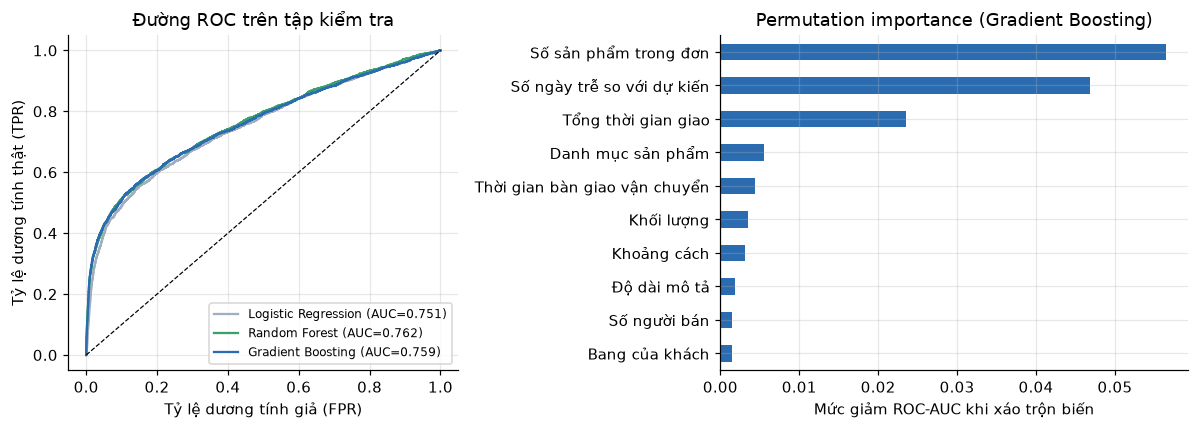

In [26]:
best = models["Gradient Boosting"]
p = probs["Gradient Boosting"]
top = p >= np.quantile(p, 0.9)   # 10% đơn có rủi ro cao nhất
R["top_decile_low_rate"] = round(yte[top].mean(), 4)
R["top_decile_capture"] = round(yte[top].sum() / yte.sum(), 4)
print(f"Tỷ lệ đánh giá thấp trong 10% đơn rủi ro nhất: {yte[top].mean():.1%} (trung bình {yte.mean():.1%})")
print(f"Nhóm này chứa {R['top_decile_capture']:.1%} tổng số đánh giá thấp")

pi = permutation_importance(best, Xte, yte, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
R["perm_importance"] = imp.head(12).round(4).to_dict()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.2]})
for (name, pr), col in zip(probs.items(), [GREY, "#38a169", MAIN]):
    fpr, tpr, _ = roc_curve(yte, pr)
    a1.plot(fpr, tpr, color=col, label=f"{name} (AUC={res[name]['roc_auc']:.3f})")
a1.plot([0, 1], [0, 1], ls="--", color="black", lw=0.8)
a1.set_xlabel("Tỷ lệ dương tính giả (FPR)"); a1.set_ylabel("Tỷ lệ dương tính thật (TPR)")
a1.set_title("Đường ROC trên tập kiểm tra")
a1.legend(fontsize=8)
VI = {"n_items": "Số sản phẩm trong đơn", "delay_days": "Số ngày trễ so với dự kiến", "delivery_days": "Tổng thời gian giao",
      "category_grp": "Danh mục sản phẩm", "carrier_days": "Thời gian bàn giao vận chuyển", "weight": "Khối lượng",
      "distance_km": "Khoảng cách", "desc_len": "Độ dài mô tả", "n_sellers": "Số người bán", "customer_state": "Bang của khách",
      "photos": "Số ảnh", "price": "Giá", "estimated_days": "Thời gian giao dự kiến", "is_late": "Giao trễ (0/1)",
      "approve_hours": "Thời gian duyệt", "freight": "Phí vận chuyển", "freight_ratio": "Tỷ lệ phí vận chuyển",
      "same_state": "Cùng bang", "installments": "Số kỳ trả góp", "purchase_month": "Tháng mua",
      "purchase_dow": "Thứ trong tuần", "payment_type": "Phương thức thanh toán"}
imp.head(10).rename(VI)[::-1].plot.barh(ax=a2, color=MAIN)
a2.set_xlabel("Mức giảm ROC-AUC khi xáo trộn biến"); a2.set_title("Permutation importance (Gradient Boosting)")
save("10_roc_importance")

In [27]:
lr = models["Logistic Regression"]
R["lr_coef"] = pd.Series(lr[-1].coef_[0][:len(num)], index=num).sort_values().round(3).to_dict()
pd.Series(R["lr_coef"], name="hệ số (biến đã chuẩn hóa)").to_frame()

,hệ số (biến đã chuẩn hóa)
distance_km,-0.04
purchase_month,-0.04
approve_hours,-0.02
freight,-0.02
desc_len,-0.01
purchase_dow,-0.01
photos,-0.00
weight,0.01
price,0.03
freight_ratio,0.03


In [28]:
(OUT / "results.json").write_text(json.dumps(R, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print("Đã lưu", OUT / "results.json")

Đã lưu outputs\results.json
